# plot CDF and/or PDF of input layer
- what 
    - pdf/ or histogram counts 
    - CDF
        - descending order for BT => giving probability of BT value below threshold 
        - ascending order for precip => probability above threshold 
        => these are the extreme pixel values i look at my analysis
    - for BT, Precip and IWP
- input: histogram values from `nbook/42_xx`
- output: pdf/cdf plots (inputlayer comparison)


In [1]:
import sys
sys.path.append("../tools")

import handle_OBS_data as ob
import handle_ICON_data as ic
import inputlayer


import xarray as xr

# plotting
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import seaborn as sns

import os


# for dat creation 
import pandas as pd

### styling parameter

In [2]:
from defs_application import *

# inputs

In [3]:
input_dir = "../output/cdf/data/" # old


types = ["histograms","cdfs"]
variables = ["tb","precip","iwp","rlut"]

plotlabel= "June 2023"
plot_save_name = "2023-06"

startdate = "2023-06-01-00"
enddate =  "2023-06-30-21" #"2023-06-30-21" 

dates = ob.create_3h_timestamps(startdate, enddate)

dates_array = np.array(dates)
bad_timesteps_str = bad_timesteps.strftime('%Y-%m-%d-%H%M').tolist()
dates = dates_array[~np.isin(dates_array, bad_timesteps_str)].tolist()



data = {typ: {} for typ in types} 
for typ in types: 
    for variable in variables: 
        filepaths = [os.path.join(input_dir, f"{typ}_{variable}_{date}.nc") for date in dates]
        data[typ][variable] = xr.open_mfdataset(filepaths).compute() # compute so the annoying sh print is not printed later...

filepaths = [os.path.join(input_dir, f"histograms_precip_amount_{date}.nc") for date in dates]
data["histograms"]["precip_amount"] = xr.open_mfdataset(filepaths).compute()


In [4]:
# savedir plots 
from pathlib import Path
outputdir =Path("../output/plots/cdf/")
# create main directory
outputdir.mkdir(parents=True, exist_ok=True)

# Plots 

## 1. Counts

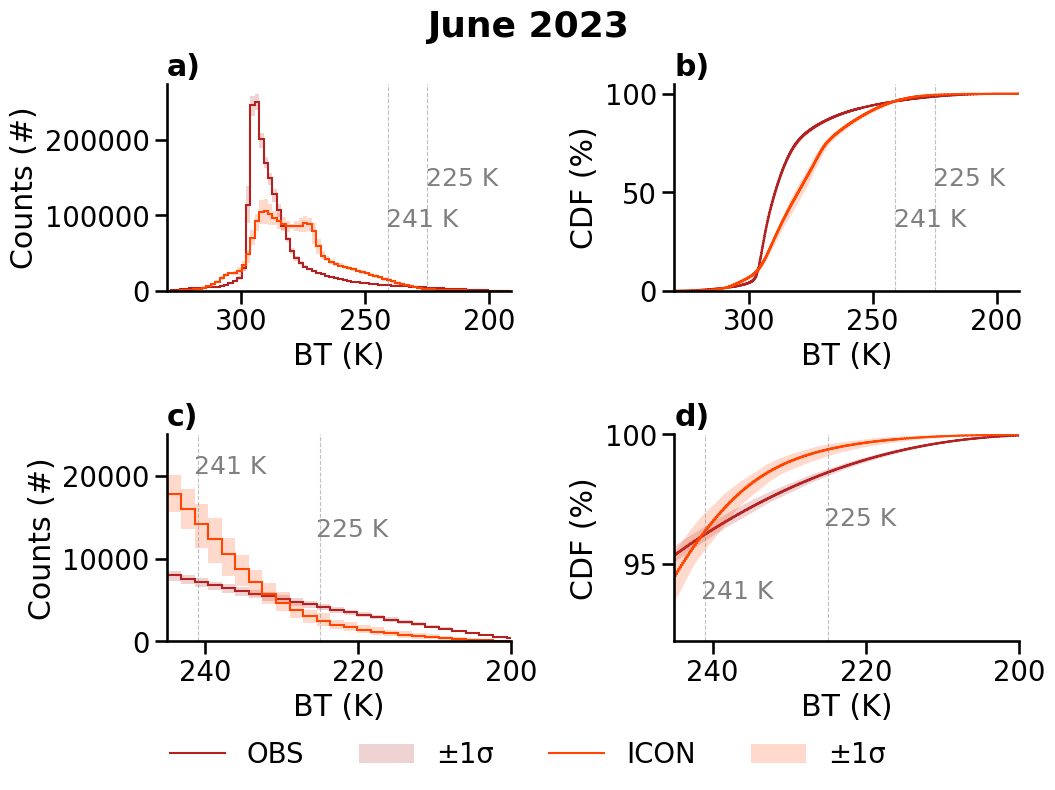

In [6]:
sns.set_context("talk", font_scale = 1.2)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

inputlayer.plot_pdf_pair( ax=axes[0,0], data_list=[data["histograms"]["tb"]["counts_tb_OBS"], data["histograms"]["tb"]["counts_tb_ICON"]], 
                alltimestamps = False, main = True, uncertainty = True,
               percentiles =(0.16,0.84),
               colors=[color_tb_obs, color_tb_icon],
               labels=["OBS", "ICON"], xlabel="BT (K)",ylabel = "Counts (#)", 
               vlines=[(225, "225 K",0.6), (241, "241 K",0.4)], 
               invert_x=True, xlim=(191,330),
               title = "a)", legend = False)

inputlayer.plot_pdf_pair( ax=axes[0,1], data_list=[data["cdfs"]["tb"]["cdf_counts_tb_OBS"], data["cdfs"]["tb"]["cdf_counts_tb_ICON"]], 
               alltimestamps = False, main = True, uncertainty = True,
               percentiles =(0.16,0.84),
               cdf = True,
               colors=[color_tb_obs, color_tb_icon],
               labels=["OBS", "ICON"], xlabel="BT (K)",ylabel = "CDF (%)", 
               vlines=[(225, "225 K",0.6), (241, "241 K",0.4)], 
               invert_x=True,xlim=(191,330),
               title = "b)", legend = False)

inputlayer.plot_pdf_pair( ax=axes[1,0], data_list=[data["histograms"]["tb"]["counts_tb_OBS"], data["histograms"]["tb"]["counts_tb_ICON"]], 
               alltimestamps = False, main = True, uncertainty = True,
               percentiles =(0.16,0.84),
               colors=[color_tb_obs, color_tb_icon],
               labels=["OBS", "ICON"], xlabel="BT (K)",ylabel = "Counts (#)", 
               vlines=[(225, "225 K",0.6), (241, "241 K",0.9)], 
               invert_x=True, xlim=(200,245),ylim = (0,25000),
               title = "c)", legend = False)



inputlayer.plot_pdf_pair( ax=axes[1,1], data_list=[data["cdfs"]["tb"]["cdf_counts_tb_OBS"], data["cdfs"]["tb"]["cdf_counts_tb_ICON"]], 
               alltimestamps = False, main = True, uncertainty = True,
               percentiles =(0.16,0.84),
               cdf = True,
               colors=[color_tb_obs, color_tb_icon],
               labels=["OBS", "ICON"], xlabel="BT (K)",ylabel = "CDF (%)", 
               vlines=[(225, "225 K",0.65), (241, "241 K",0.3)], 
               invert_x=True,xlim=(200,245),ylim=(0.92,1),
               title = "d)", legend = False)

handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.05),  # slightly below the plots
           ncol=len(labels),
           frameon=False)

fig.suptitle(f"{plotlabel}", fontweight="bold", y=0.93)
plt.tight_layout()

fig.savefig(os.path.join(outputdir,f"cdf_BT_{plot_save_name}.pdf"), bbox_inches="tight")
plt.show()


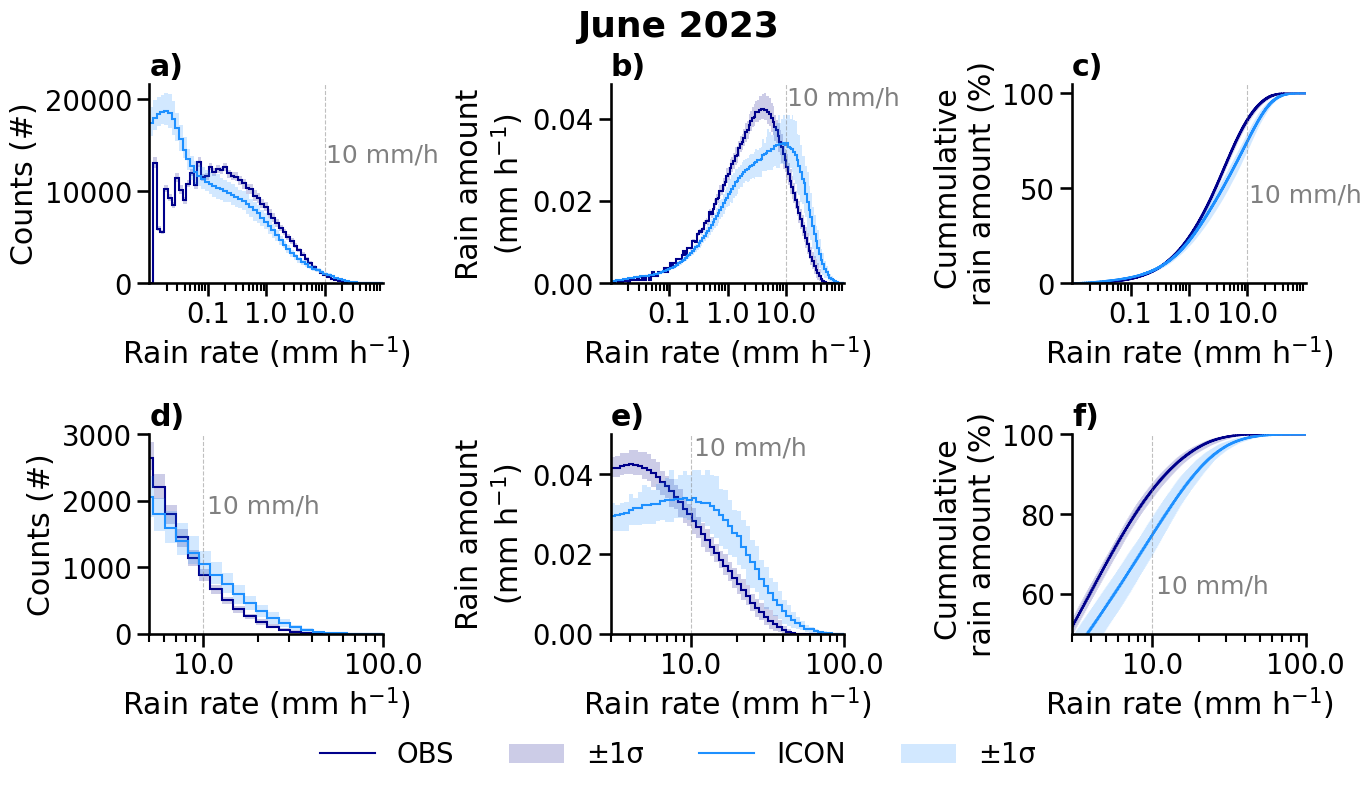

In [7]:
sns.set_context("talk", font_scale = 1.2)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# top row
inputlayer.plot_pdf_pair(ax=axes[0,0],
    data_list=[data["histograms"]["precip"]["counts_precip_OBS"], data["histograms"]["precip"]["counts_precip_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Rain rate (mm h$^{-1}$)", ylabel="Counts (#)",
    vlines=[(10, "10 mm/h", 0.7)],#(5, "5 mm/h", 0.6), (
    xscale="log", xlim=(1e-2+0.00001, 1e2-0.1),
    title="a)", legend = False)

inputlayer.plot_pdf_pair(ax=axes[0,1],
    data_list=[data["histograms"]["precip_amount"]["contri_precip_OBS"], data["histograms"]["precip_amount"]["contri_precip_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Rain rate (mm h$^{-1}$)", ylabel="Rain amount\n(mm h$^{-1}$)",
    vlines=[ (10, "10 mm/h", 0.99)],#(5, "5 mm/h", 0.9),
    xscale="log", xlim=(1e-2+0.00001, 1e2-0.1),
    title="b)", legend = False)

inputlayer.plot_pdf_pair(ax=axes[0,2],
    data_list=[data["cdfs"]["precip"]["cdf_contri_precip_OBS"], data["cdfs"]["precip"]["cdf_contri_precip_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    cdf=True,
    colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Rain rate (mm h$^{-1}$)", ylabel="Cummulative \nrain amount (%)",
    vlines=[ (10, "10 mm/h", 0.5)],#(5, "5 mm/h", 0.4),
    xscale="log", xlim=(1e-2+0.00001, 1e2-0.1),
    title="c)", legend = False)

# zoom
inputlayer.plot_pdf_pair(ax=axes[1,0],
    data_list=[data["histograms"]["precip"]["counts_precip_OBS"], data["histograms"]["precip"]["counts_precip_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Rain rate (mm h$^{-1}$)", ylabel="Counts (#)",
    vlines=[ (10, "10 mm/h", 0.7)],#(5, "5 mm/h", 0.6),
    xscale="log", xlim=(5, 100), ylim=(0, 3000),
    title="d)", legend = False)

inputlayer.plot_pdf_pair(ax=axes[1,1],
    data_list=[data["histograms"]["precip_amount"]["contri_precip_OBS"], data["histograms"]["precip_amount"]["contri_precip_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Rain rate (mm h$^{-1}$)", ylabel="Rain amount\n(mm h$^{-1}$)",
    vlines=[(10, "10 mm/h", 0.99)],#(5, "5 mm/h", 0.4), 
    xscale="log", xlim=(3, 100), ylim=(0, 0.05),
    title="e)", legend = False)

inputlayer.plot_pdf_pair(ax=axes[1,2],
    data_list=[data["cdfs"]["precip"]["cdf_contri_precip_OBS"], data["cdfs"]["precip"]["cdf_contri_precip_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    cdf=True,
    colors=[color_precip_obs, color_precip_icon],
    labels=["OBS", "ICON"], xlabel="Rain rate (mm h$^{-1}$)", ylabel="Cummulative \nrain amount (%)",
    vlines=[(10, "10 mm/h", 0.3)],#(5, "5 mm/h", 0.99)
    xscale="log", xlim=(3, 100), ylim=(0.5, 1),
    title="f)", legend = False)

handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.05),  # slightly below the plots
           ncol=len(labels),
           frameon=False)

fig.suptitle(f"{plotlabel}", fontweight="bold", y=0.93)
plt.tight_layout()
fig.savefig(os.path.join(outputdir, f"cdf_precip_{plot_save_name}.pdf"), bbox_inches="tight")
plt.show()

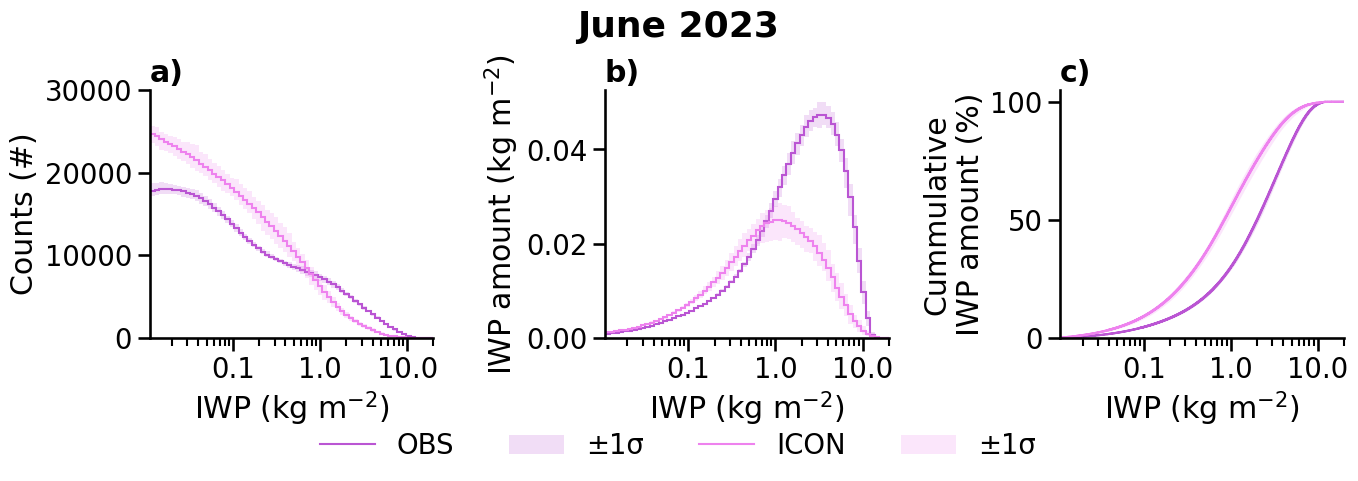

In [8]:
sns.set_context("talk",font_scale = 1.2)
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

inputlayer.plot_pdf_pair(ax=axes[0],
    data_list=[data["histograms"]["iwp"]["counts_iwp_OBS"], data["histograms"]["iwp"]["counts_iwp_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_iwp_obs, color_iwp_icon],
    labels=["OBS", "ICON"], xlabel="IWP (kg m$^{-2}$)", ylabel="Counts (#)",
    xscale="log", xlim=(1e-2+0.001, 20), ylim=(0, 30000),
    title="a)", legend = False)

inputlayer.plot_pdf_pair(ax=axes[1],
    data_list=[data["histograms"]["iwp"]["contri_iwp_OBS"], data["histograms"]["iwp"]["contri_iwp_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_iwp_obs, color_iwp_icon],
    labels=["OBS", "ICON"], xlabel="IWP (kg m$^{-2}$)", ylabel="IWP amount (kg m$^{-2}$)",
    xscale="log", xlim=(1e-2+0.001, 20),# ylim=(0, 20000),
    title="b)", legend = False)

inputlayer.plot_pdf_pair(ax=axes[2],
    data_list=[data["cdfs"]["iwp"]["cdf_contri_iwp_OBS"], data["cdfs"]["iwp"]["cdf_contri_iwp_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    cdf=True,
    colors=[color_iwp_obs, color_iwp_icon],
    labels=["OBS", "ICON"], xlabel="IWP (kg m$^{-2}$)", ylabel="Cummulative\nIWP amount (%)",
    xscale="log", xlim=(1e-2+0.001, 20),
    title="c)", legend = False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.05),  # slightly below the plots
           ncol=len(labels),
           frameon=False)

fig.suptitle(f"{plotlabel}", fontweight="bold", y=0.9)
plt.tight_layout()
fig.savefig(os.path.join(outputdir, f"cdf_iwp_{plot_save_name}.pdf"), bbox_inches="tight")
plt.show()

In [9]:
# rlut

['ICON', '±1σ', 'ICON-Tf', '±1σ', 'ICON-Tb', '±1σ', 'OBS', '±1σ']


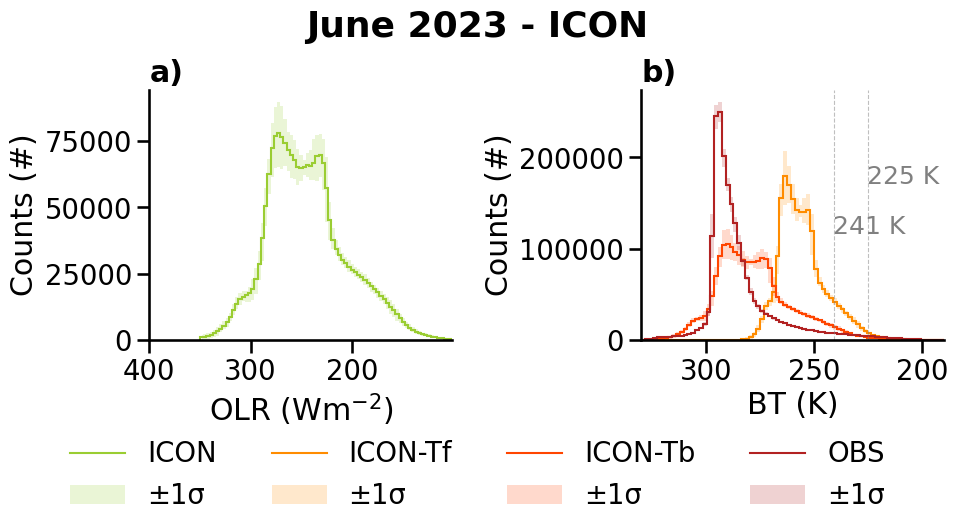

In [10]:
sns.set_context("talk",font_scale = 1.2)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

inputlayer.plot_pdf_pair(ax=axes[0],
    data_list=[data["histograms"]["rlut"]["counts_rlut_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_rlut_icon],
    labels=["ICON"], xlabel="OLR (Wm$^{-2}$)", ylabel="Counts (#)",
    invert_x=True, xlim=(101, 400),
    title="a)", legend = False)

# inputlayer.plot_pdf_pair(ax=axes[0,1],
#     data_list=[data["cdfs"]["rlut"]["cdf_counts_rlut_ICON"]],
#     alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
#     cdf=True, invert_x=True,
#     colors=[color_rlut_icon],
#     labels=["ICON"], xlabel="OLR (Wm$^{-2}$)", ylabel="CDF (%)",
#     xlim=(101, 400),
#     title="b)", legend = False)

inputlayer.plot_pdf_pair(ax=axes[1],
    data_list=[data["histograms"]["tb"]["counts_tf_ICON"],
               data["histograms"]["tb"]["counts_tb_ICON"],
               data["histograms"]["tb"]["counts_tb_OBS"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_tf_icon, color_tb_icon, color_tb_obs],
    labels=["ICON-Tf", "ICON-Tb", "OBS"], xlabel="BT (K)", ylabel="Counts (#)",
    vlines=[(225, "225 K", 0.7), (241, "241 K", 0.5)],
    invert_x=True, xlim=(190, 330),
    title="b)", legend = False)

# inputlayer.plot_pdf_pair(ax=axes[1,1],
#     data_list=[data["cdfs"]["tb"]["cdf_counts_tf_ICON"],
#                data["cdfs"]["tb"]["cdf_counts_tb_ICON"],
#                data["cdfs"]["tb"]["cdf_counts_tb_OBS"]],
#     alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
#     cdf=True, invert_x=True,
#     colors=[color_tf_icon, color_tb_icon, color_tb_obs],
#     labels=["ICON-Tf", "ICON-Tb", "OBS"], xlabel="BT (K)", ylabel="CDF (%)",
#     vlines=[(225, "225 K", 0.7), (241, "241 K", 0.6)],
#     xlim=(200, 330),
#     title="d)", legend = False)

handles, labels = [], []
for ax in [axes[0], axes[1]]:
    for h, l in zip(*ax.get_legend_handles_labels()):
        handles.append(h)
        labels.append(l)


fig.legend(handles, labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.15),
           #ncol=len(labels),
            ncol=len(labels)//2,
           frameon=False)
print(labels)

fig.suptitle(f"{plotlabel} - ICON", fontweight="bold", y=0.9)
plt.tight_layout()
fig.savefig(os.path.join(outputdir, f"cdf_icon_bts_{plot_save_name}.pdf"), bbox_inches="tight")
plt.show()

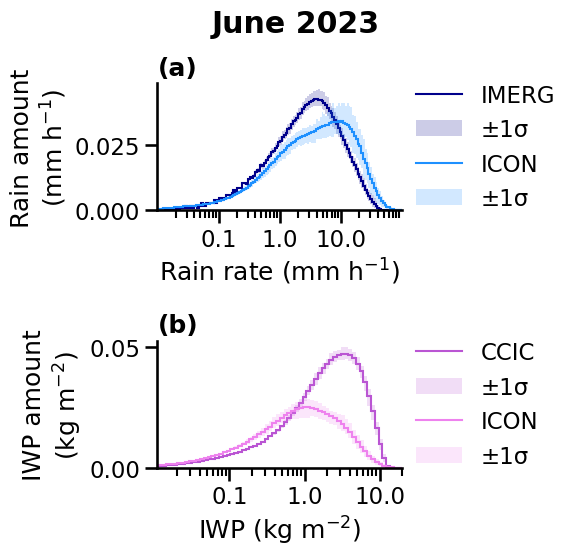

In [11]:
sns.set_context("talk")
fig, axes = plt.subplots(2, 1, figsize=(6,6))


inputlayer.plot_pdf_pair(ax=axes[0],
    data_list=[data["histograms"]["precip_amount"]["contri_precip_OBS"], data["histograms"]["precip_amount"]["contri_precip_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_precip_obs, color_precip_icon],
    labels=["IMERG", "ICON"], xlabel="Rain rate (mm h$^{-1}$)", ylabel="Rain amount\n(mm h$^{-1}$)",
    #vlines=[ (10, "10 mm/h", 0.99)],#(5, "5 mm/h", 0.9),
    xscale="log", xlim=(1e-2+0.00001, 1e2-0.1),
    title="(a)", legend = False)

inputlayer.plot_pdf_pair(ax=axes[1],
    data_list=[data["histograms"]["iwp"]["contri_iwp_OBS"], data["histograms"]["iwp"]["contri_iwp_ICON"]],
    alltimestamps=False, main=True, uncertainty=True, percentiles=(0.16, 0.84),
    colors=[color_iwp_obs, color_iwp_icon],
    labels=["CCIC", "ICON"], xlabel="IWP (kg m$^{-2}$)", ylabel="IWP amount\n(kg m$^{-2}$)",
    xscale="log", xlim=(1e-2+0.001, 20),# ylim=(0, 20000),
    title="(b)", legend = False)



# Individual legend next to each subplot
for ax in axes:
    h, l = ax.get_legend_handles_labels()
    ax.legend(h, l,
              loc="center left",
              bbox_to_anchor=(1.02, 0.5),
              frameon=False,
              borderaxespad=0)

fig.suptitle(f"{plotlabel}", fontweight="bold", y=0.94)
plt.tight_layout()
fig.savefig("./pdfs_contri_poster.png", bbox_inches="tight")
plt.show()